# Hyrax-SELDON Example with Lasair

Notebook demonstrates using Hyrax-Alerts to consume alerts from the Lasair LSST broker
and process them with Hyrax-SELDON.

In [ ]:
from hyrax_alerts.process_alerts import process_alerts

process_alerts(config_filepath="./lasair_hyrax_seldon_config.toml")

All migrations complete. Your configuration file is now up to date with the latest schema. The runtime config saved in the output directory will reflect the new schema, and your original config file will remain unchanged on disk.
Runtime config contains key or section 'pre_process' which has no default defined. All configuration keys and sections must be defined in /home/drew/code/hyrax/src/hyrax/hyrax_default_config.toml
Runtime config contains key or section 'pre_filter' which has no default defined. All configuration keys and sections must be defined in /home/drew/code/hyrax/src/hyrax/hyrax_default_config.toml
Runtime config contains key or section 'writers' which has no default defined. All configuration keys and sections must be defined in /home/drew/code/hyrax/src/hyrax/hyrax_default_config.toml
[2026-11-20 12:53:10,937 hyrax.alerts.writers.writer_utils:INFO] Created writer 'to_disk_0' of class 'HyraxAlertsDiskWriter'
[2026-11-20 12:53:12,748 hyrax.models.model_registry:INFO] Set

Example post-processing function called.
Example post-filtering function called.


[2026-11-20 12:53:35,742 hyrax.alerts.process_alerts:INFO] Processing batch 2 with size 76


Example post-processing function called.
Example post-filtering function called.


[2026-11-20 12:53:41,733 hyrax.alerts.consumers.base_consumer:INFO] Removed 2 of 68 items from batch with pre_filter.
[2026-11-20 12:53:41,743 hyrax.alerts.process_alerts:INFO] Processing batch 3 with size 66


Example post-processing function called.
Example post-filtering function called.


... (7 outputs left out)

Example post-processing function called.
Example post-filtering function called.


[2026-11-20 12:54:11,669 hyrax.alerts.process_alerts:INFO] Processing batch 8 with size 39


Example post-processing function called.
Example post-filtering function called.


[2026-11-20 12:54:17,821 hyrax.alerts.consumers.base_consumer:INFO] Removed 3 of 99 items from batch with pre_filter.
[2026-11-20 12:54:17,843 hyrax.alerts.process_alerts:INFO] Processing batch 9 with size 96
[2026-11-20 12:54:17,843 hyrax.alerts.process_alerts:INFO] Alert limit of 500 reached. Stopping processing.
[2026-11-20 12:54:17,844 hyrax.datasets.kafka_stream_dataset:INFO] Kafka partitions revoked: ['lasair_201DrewsLSSTvariables[0]', 'lasair_201DrewsLSSTvariables[1]', 'lasair_201DrewsLSSTvariables[2]', 'lasair_201DrewsLSSTvariables[3]', 'lasair_201DrewsLSSTvariables[4]', 'lasair_201DrewsLSSTvariables[5]', 'lasair_201DrewsLSSTvariables[6]', 'lasair_201DrewsLSSTvariables[7]']
[2026-11-20 12:54:18,012 hyrax.datasets.result_dataset:INFO] Optimizing Lance table after 8 batches
[2026-11-20 12:54:18,073 hyrax.datasets.result_dataset:INFO] Lance table optimization complete
[2026-11-20 12:54:18,078 hyrax.verbs.infer_stream:INFO] InferStream session closed.


In [2]:
from hyrax import Hyrax
from hyrax.datasets.result_dataset import ResultDataset
from hyrax.config_utils import find_most_recent_results_dir

h = Hyrax()
infer_dir = find_most_recent_results_dir(h.config, "infer_stream")
a = ResultDataset({}, data_location = infer_dir)

In [3]:
from hyrax.config_utils import find_most_recent_results_dir

infer_dir = str(find_most_recent_results_dir(h.config, "infer_stream"))

data_request = {
    "reduce_dimensions": {
        "data": {
            "dataset_class": "ResultDataset",
            "data_location": infer_dir,
            "primary_id_field": "id",
            "fields": ['z'],
        }
    }
}

h.set_config("data_request", data_request)

umap_results = h.reduce_dimensions(algorithm="umap")

[2026-11-20 12:54:18,606 hyrax.verbs.reduce_dimensions:INFO] Saving reduction results using umap to /home/drew/code/hyrax_seldon/docs/pre_executed/results/20261120-125418-umap-9Ozd
[2026-11-20 12:54:18,607 hyrax.verbs.reduce_dimensions:INFO] Using configured [data_request.reduce_dimensions] to load dataset for reduction.
[2026-11-20 12:54:18,612 hyrax.verbs.reduce_dimensions:INFO] Using field 'z' for dimensionality reduction.
[2026-11-20 12:54:19,118 hyrax.verbs.reduce_dimensions:INFO] No model_path specified. A new model will be fitted.
[2026-11-20 12:54:19,119 hyrax.verbs.reduction_algorithms.umap:INFO] Fitting the UMAP
[2026-11-20 12:54:24,895 hyrax.verbs.reduce_dimensions:INFO] Saving fitted umap reducer to result directory


Creating lower dimensional representation using UMAP::   0%|          | 0/1 [00:00<?, ?it/s]

[2026-11-20 12:54:27,897 hyrax.datasets.result_dataset:INFO] Optimizing Lance table after 1 batches
[2026-11-20 12:54:27,901 hyrax.datasets.result_dataset:INFO] Lance table optimization complete
[2026-11-20 12:54:27,902 hyrax.verbs.reduce_dimensions:INFO] Finished transforming all data with umap


In [4]:
import numpy as np

# Stack all UMAP embeddings into a single array.
umap_embeddings = np.array([umap_results[i]["data"] for i in range(len(umap_results))])
print(f"Shape: {umap_embeddings.shape}  (samples × components)")

Shape: (459, 2)  (samples × components)


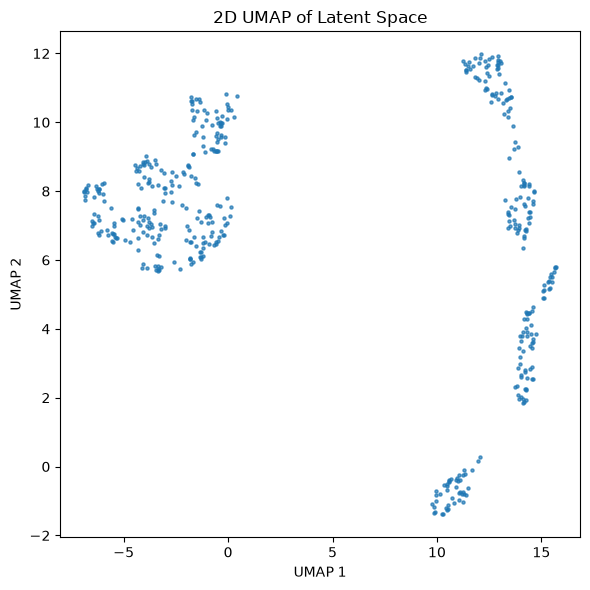

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(umap_embeddings[:, 0], umap_embeddings[:, 1], s=5, alpha=0.7)
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.set_title("2D UMAP of Latent Space")
plt.tight_layout()
plt.show()